# Cross-seed student distillation — results

Live analysis of `outputs/students/`, scoped to the July 2026 **cross-initialization** treatment for the **dog** trait. The teacher is fine-tuned from the original `pythia-160m` (`tseed1`) and its number data always comes from that same-init teacher, but the student is fine-tuned from a **different** initialization: at the ep20 primary dose, all six PolyPythia re-seeds (`data-seed1/2/3` — re-shuffled data order; `weight-seed1/2/3` — re-drawn initial weights). The same-init `pythia-160m` student — initialized from the same original model as the teacher — is retained as the reference group.

Cloud et al. report that subliminal transfer through number sequences largely **requires shared initialization** between the model that produced the data and the student. This notebook tests that on PolyPythias: coverage, held-out transfer per student initialization, the **student distillation-epoch dose response**, the paired collapse against the same-init reference on a shared teacher-HP grid, whether the teacher's own preference still predicts transfer under re-initialization, the teacher-hyperparameter surface across bases, and specificity.

> **Student-dose coverage.** The original slice bases (`pythia-160m`, `data-seed1`, `weight-seed2`) carry the ep1/ep2/ep5/ep10 ladder on the full ~102-tag teacher grid; the four later re-seeds (`data-seed2/3`, `weight-seed1/3`) are ep20-only. The **ep20** dose exists on the plain `prefix` template only (the spliced template stops at ep10) and is complete on all seven bases (the same-init backfill landed 2026-07-28: all ~102 teacher configs, 1 ft seed), so the primary-dose sections run with the same-init reference in place. The base × teacher-HP comparisons fix the student dose at `PRIMARY_EPOCH` (20) and do not require complete doses: marginal views (§1, §4, §6) show every base with runs at that dose (`PRIMARY_BASES`); the shared-grid paired views (§3, §5) use `GRID_BASES` — bases covering ≥ `MIN_GRID_FRAC` of the dose's teacher-tag union — so a mid-backfill base is reported and set aside rather than shrinking the grid (the `HAS_SAME_INIT` fallbacks in §1/§3/§5 remain as coverage guards for re-runs on partial data). §5b never intersects: each (init × template) grid shows all configs available to it. §2's dose curves use the all-dose intersection `DOSE_TAGS` so every point on a curve averages the same teacher configs.

> **Uncertainty warning.** Seed depth is uneven: after the top3hp reseed the cross-init ep20 cells on `data-seed1` carry 3 ft seeds (5 on the focus lineage), while the other five re-seeds and the same-init ep20 reference are mostly single-seed. Each cell contributes its across-seed mean `p(target)`; persisted across-seed CIs are not used, so spread across teacher configurations below is descriptive, not repeated-seed uncertainty. The `rng` controls now include the ep20 dose (3 ft seeds per base, test p ≈ 0.001–0.009), giving an explicit no-signal floor at the primary dose; the summaries still carry no untuned-base `p(target)`.


## Setup and artifact loader

Run from the repo root with `uv run --group analysis jupyter lab`. The loader joins every student to the exact source teacher (seed + hyperparameters that generated its number dataset) and reads that teacher's own held-out `validation` preference directly, because the students in this slice carry only the `test` and `storytelling` prompt sets (no `validation` set to pivot on). It loads **all** student distillation epochs at the fixed student LoRA; sections that compare bases against the shared teacher grid slice to `PRIMARY_EPOCH`, while §2 uses the full dose ladder.

In [1]:
from __future__ import annotations
import json, re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.analysis import frames
from subliminal_learning.analysis import student_tree
from subliminal_learning.analysis import plots as aplots

ROOT, OUTPUT_ROOT = bootstrap()
STUDENTS_ROOT = OUTPUT_ROOT / "students"

# Fixed treatment axes: one animal, one number mode, one teacher seed. Student dose (epochs) is a free axis.
# The teacher is fine-tuned from the original pythia-160m, so its numbers live under numbers_base "pythia-160m"
# (cross-seed students reach it via the `teacher-pythia-160m` lineage level).
ANIMAL, NUMBERS_BASE, TEACHER_SEED, STUDENT_SEED = "dog", "pythia-160m", 1, 1
DATASET, STUDENT_LORA = "ex10-20_prefix_n100k", "lr1e-4_r8a32"   # sibling `ex10-20_prefix_n100k_spliced` holds the prompt-spliced variant
PRIMARY_EPOCH = 20   # dose for the base x teacher-HP comparisons; ep20 exists on the plain template only (ep1/2/5/10 elsewhere, see §2)

# Student initializations, same-init reference first. The reference student shares the teacher's original pythia-160m
# initialization; the re-seeds are re-initializations: data-seed* = re-shuffled data seed, weight-seed* = re-drawn weights.
# The list self-filters to bases present in the slice — at ep20 that is now all six re-seeds plus the same-init reference.
BASE_ORDER = frames.MODEL_ORDER
BASE_LABEL = {"pythia-160m":"pythia-160m (same init)", "pythia-160m-data-seed1":"data-seed1",
              "pythia-160m-data-seed2":"data-seed2", "pythia-160m-data-seed3":"data-seed3",
              "pythia-160m-weight-seed1":"weight-seed1", "pythia-160m-weight-seed2":"weight-seed2",
              "pythia-160m-weight-seed3":"weight-seed3"}
COLOR = {"pythia-160m":"#333333", "pythia-160m-data-seed1":"#4c78a8", "pythia-160m-data-seed2":"#72b7b2",
         "pythia-160m-data-seed3":"#54a24b", "pythia-160m-weight-seed1":"#f58518",
         "pythia-160m-weight-seed2":"#e45756", "pythia-160m-weight-seed3":"#b279a2"}
set_plot_style(dpi=115, grid_alpha=0.25, hide_spines=True)
print("output_root:", OUTPUT_ROOT)

output_root: /mnt/cold-1/soar-subliminal/angela/outputs


In [2]:
# The student-tree scan (treatment + control leaves, teacher-eval attachment) lives in
# `analysis.student_tree`; this notebook selects the columns it uses from the shared superset.
# One row per (student config, prompt set). Teacher preference is attached per-config from the
# numbers-generating teacher's own eval, so it survives even when student and teacher share no prompt set.
STUDENT_TAG_RE = re.compile(rf"^ep\d+_{re.escape(STUDENT_LORA)}$")   # any epoch at the fixed student LoRA

treatments_all, n_missing_manifest, n_skipped = student_tree.load_treatments(OUTPUT_ROOT)
controls_all = student_tree.load_controls(OUTPUT_ROOT)

# Scope: fixed animal/numbers-base/teacher-seed/dataset/student-LoRA; student init and dose are the free axes.
# A config qualifies when its seed set CONTAINS STUDENT_SEED and contributes its across-seed mean p(target)
# (the top3hp reseed took cross data-seed1 ep20 cells to 3 seeds; requiring exactly (1,) would drop them all).
sel = treatments_all[treatments_all.animal.eq(ANIMAL) & treatments_all.numbers_base.eq(NUMBERS_BASE) &
                     treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.dataset.eq(DATASET) &
                     treatments_all.student_tag.map(lambda t: bool(STUDENT_TAG_RE.fullmatch(t))) &
                     treatments_all.student_seeds.map(lambda s: STUDENT_SEED in s)].copy()
assert len(sel), "selected cross-seed slice is empty"

META = ["config_id","animal","model","numbers_base","cross_init","teacher_tag","teacher_seed","dataset","student_tag",
        "student_epochs","teacher_epochs","teacher_lr","teacher_rank","teacher_alpha","teacher_validation",
        "teacher_favorite","teacher_off_topic","n_train","loss","steps"]
wide = sel.drop_duplicates("config_id")[META].set_index("config_id")
wide = wide.join(sel.pivot(index="config_id", columns="set", values="p").add_prefix("student_"))
wide = wide.join(sel.pivot(index="config_id", columns="set", values="base_p").add_prefix("untuned_"))
wide = wide.reset_index()
wide["teacher_lora"] = wide.apply(lambda x:f"r{x.teacher_rank}/α{x.teacher_alpha}", axis=1)
wide["init_class"] = np.where(wide.cross_init, "cross-init", "same-init")
# Optional student prompt sets. The dog students (all initializations) carry only `test` and `storytelling`; ensure the
# richer student columns exist (as NaN) so downstream panels degrade to empty instead of raising on a missing column.
for _col in ["student_off_topic", "student_validation", "student_storytelling", "untuned_off_topic"]:
    if _col not in wide.columns: wide[_col] = np.nan
wide["test_minus_offtopic"] = wide.student_test - wide.student_off_topic
BASES = [b for b in BASE_ORDER if b in set(wide.model)]
SAME_INIT_MODEL = NUMBERS_BASE
assert not wide.duplicated(["model","teacher_tag","student_epochs"]).any(), "duplicate (base, teacher-HP, dose) rows would pool distinct runs"

# Primary-dose slice used by the base x teacher-HP comparisons (§1, §3-§6); §2 uses the full dose ladder in `wide`.
# Not every base necessarily has runs at the primary dose (e.g. ep20 was run cross-init first), so marginal views
# (§1, §4, §6) operate on PRIMARY_BASES (any runs at the dose), while the shared-grid paired views (§3, §5) operate
# on GRID_BASES: bases covering >= MIN_GRID_FRAC of the dose's teacher-tag union. A base whose backfill at this dose
# is only partially complete would otherwise shrink COMMON_TAGS to whatever happens to be done — so it is excluded
# from the grid (reported below) until its coverage catches up; HAS_SAME_INIT tracks the same-init reference.
MIN_GRID_FRAC = 0.5
primary = wide[wide.student_epochs.eq(PRIMARY_EPOCH)].copy()
assert len(primary), f"no configs at PRIMARY_EPOCH={PRIMARY_EPOCH}"
assert not primary.duplicated(["model","teacher_tag"]).any(), "duplicate (base, teacher-HP) rows at the primary dose"
PRIMARY_BASES = [b for b in BASES if b in set(primary.model)]
_n_union = primary.teacher_tag.nunique()
_n_by_base = primary.groupby("model").teacher_tag.nunique()
GRID_BASES = [b for b in PRIMARY_BASES if _n_by_base[b] >= MIN_GRID_FRAC * _n_union]
assert GRID_BASES, "no base covers enough of the primary dose to define a shared grid"
for b in PRIMARY_BASES:
    if b not in GRID_BASES:
        print(f"NOTE: {BASE_LABEL[b]} has only {_n_by_base[b]}/{_n_union} teacher configs at ep={PRIMARY_EPOCH} "
              f"(< {MIN_GRID_FRAC:.0%}) — kept in marginal views, excluded from the shared grid (§3, §5)")
HAS_SAME_INIT = SAME_INIT_MODEL in GRID_BASES
if not HAS_SAME_INIT:
    print(f"NOTE: same-init ({SAME_INIT_MODEL}) is missing or too sparse at ep={PRIMARY_EPOCH} — "
          f"paired-against-same-init views (§3, §5 ordering, Δ columns) are skipped/reduced")
# Teacher configs completed for EVERY grid base at the primary dose — the shared grid reused across sections.
pv_primary = primary.pivot_table(index="teacher_tag", columns="model", values="student_test")
COMMON_TAGS = pv_primary.dropna(subset=GRID_BASES).index
assert len(COMMON_TAGS), "no teacher configs shared across all grid bases at the primary dose"

controls = controls_all[controls_all.animal.eq(ANIMAL) & controls_all.dataset.eq(DATASET) &
                        controls_all.model.isin(BASES) & controls_all.set.eq("test")].copy()
if n_missing_manifest: print(f"{n_missing_manifest} runs missing train_manifest.json (metadata only; not excluded)")
if n_skipped: print(f"{n_skipped} dirs skipped by layout/regex filters")
print(f"{len(wide)} configs over doses {sorted(wide.student_epochs.unique())}; {len(primary)} at primary ep={PRIMARY_EPOCH}")
print(f"{len(BASES)} student inits ({len(PRIMARY_BASES)} at the primary dose, {len(GRID_BASES)} on the shared grid); "
      f"{len(COMMON_TAGS)} teacher HP tags shared across the grid bases; {len(controls)} control students")
print("student sets present:", sorted(sel["set"].unique()))

233 dirs skipped by layout/regex filters
1941 configs over doses [np.int64(1), np.int64(2), np.int64(5), np.int64(10), np.int64(20), np.int64(40)]; 713 at primary ep=20
7 student inits (7 at the primary dose, 7 on the shared grid); 101 teacher HP tags shared across the grid bases; 69 control students
student sets present: ['storytelling', 'test']


## 1. Inventory and held-out transfer by student initialization

A config is one `(student base × teacher HP)` result at the primary student dose (ep{PRIMARY_EPOCH}). The coverage table shows how many configs each initialization has at each **student distillation epoch** — the original slice bases (`pythia-160m`, `data-seed1`, `weight-seed2`) carry the ep1/ep2/ep5/ep10 ladder on the full teacher grid, the four later re-seeds (`data-seed2/3`, `weight-seed1/3`) are ep20-only, and the plain-template ep20 dose is complete on all seven bases (the same-init backfill landed 2026-07-28). `test` is the main held-out preference metric; each strip is one student initialization present at the primary dose. The red markers are the dose-matched ep{PRIMARY_EPOCH} `rng` control students (3 ft seeds per base); no untuned-base `p(target)` was persisted, so compare inits against each other, the controls, and the ep1 levels in §2.


,student ep1,student ep2,student ep5,student ep10,student ep20,student ep40
pythia-160m (same init),102,102,102,102,102,0
data-seed1,102,102,102,102,102,1
data-seed2,0,0,0,0,102,0
data-seed3,0,0,0,0,102,0
weight-seed1,0,0,3,0,102,0
weight-seed2,102,102,102,102,101,0
weight-seed3,0,0,0,0,102,0


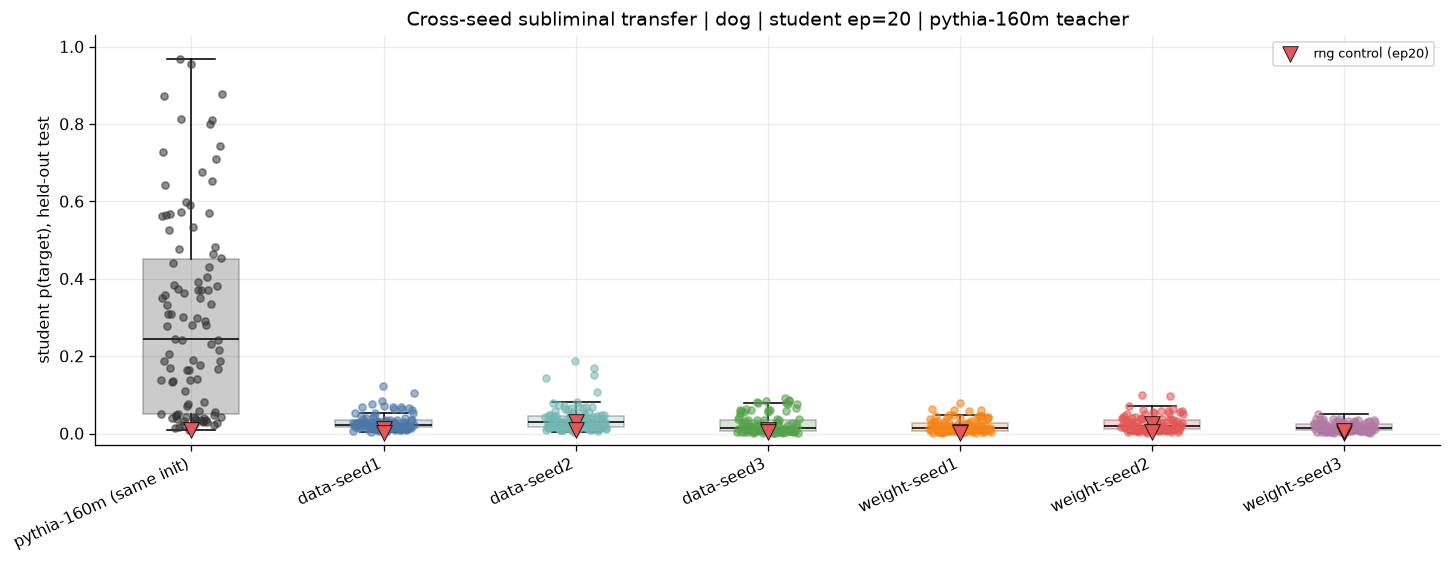

,class,n,test mean,test median,test max,Δ mean vs same-init,rng control
student init,,,,,,,
pythia-160m (same init),same-init,102,0.298,0.243,0.968,0.000,0.009
data-seed1,cross-init,102,0.029,0.023,0.123,-0.269,0.011
data-seed2,cross-init,102,0.037,0.029,0.188,-0.261,0.029
data-seed3,cross-init,102,0.025,0.013,0.093,-0.273,0.008
weight-seed1,cross-init,102,0.020,0.013,0.079,-0.278,0.004
weight-seed2,cross-init,101,0.025,0.019,0.101,-0.273,0.025
weight-seed3,cross-init,102,0.017,0.015,0.051,-0.281,0.002


In [3]:
coverage = pd.crosstab(wide.model, wide.student_epochs)
coverage.index = [BASE_LABEL.get(x,x) for x in coverage.index]
coverage.columns = [f"student ep{c}" for c in coverage.columns]
display(coverage.style.set_caption("Configs per student init × distillation epochs (all doses)"))

ctrl20 = controls[controls.student_epochs.eq(PRIMARY_EPOCH)]   # dose-matched rng controls (3 ft seeds per base)
fig, ax = plt.subplots(figsize=(1.55*len(PRIMARY_BASES)+2, 5))
for i, b in enumerate(PRIMARY_BASES):
    v = primary.loc[primary.model.eq(b), "student_test"].dropna().values
    ax.boxplot([v], positions=[i], widths=.5, patch_artist=True, showfliers=False,
               boxprops={"facecolor":COLOR[b], "alpha":.25}, medianprops={"color":"black"})
    jitter = np.linspace(-.16,.16,len(v)) if len(v)>1 else [0]
    ax.scatter(i+jitter, v, s=20, alpha=.55, color=COLOR[b], zorder=3)
    c = ctrl20.loc[ctrl20.model.eq(b), "p"].dropna()
    if len(c): ax.scatter([i]*len(c), c, marker="v", s=95, color="#e45756", edgecolor="black", lw=.5, zorder=5)
ut = primary.untuned_test.dropna()
if len(ut): ax.axhline(ut.iloc[0], color=".35", ls=":", label="untuned base (same-init)")
if len(ctrl20):
    ax.scatter([], [], marker="v", s=95, color="#e45756", edgecolor="black", lw=.5, label=f"rng control (ep{PRIMARY_EPOCH})")
ax.set(xticks=range(len(PRIMARY_BASES)), ylim=(-.03,1.03), ylabel="student p(target), held-out test",
       title=f"Cross-seed subliminal transfer | {ANIMAL} | student ep={PRIMARY_EPOCH} | {NUMBERS_BASE} teacher")
ax.set_xticklabels([BASE_LABEL[b] for b in PRIMARY_BASES], rotation=25, ha="right")
if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

summary = []
same_mean = (primary.loc[primary.model.eq(SAME_INIT_MODEL), "student_test"].mean()
             if HAS_SAME_INIT else np.nan)   # Δ column renders NaN until same-init ep{PRIMARY_EPOCH} runs exist
for b in PRIMARY_BASES:
    s = primary.loc[primary.model.eq(b), "student_test"].dropna()
    c = ctrl20.loc[ctrl20.model.eq(b), "p"].dropna()
    summary.append({"student init":BASE_LABEL[b], "class":"same-init" if b==SAME_INIT_MODEL else "cross-init",
                    "n":len(s), "test mean":s.mean(), "test median":s.median(), "test max":s.max(),
                    "Δ mean vs same-init":s.mean()-same_mean, "rng control":c.iloc[0] if len(c) else np.nan})
sdf = pd.DataFrame(summary).set_index("student init")
display(sdf.style.format({c:"{:.3f}" for c in sdf.columns if c not in ("class","n")}, na_rep="–")
        .set_caption(f"Transfer by student initialization (ep={PRIMARY_EPOCH})"))

## 2. Student distillation-epoch dose response

How does held-out transfer grow with the number of **student** fine-tuning epochs? To keep doses comparable, the curves below are computed on the fixed set of teacher configs shared by every substantially-covered `(base, dose)` cell (`DOSE_TAGS` — stricter than the primary-dose `COMMON_TAGS` grid, because coverage differs by dose); every point on a curve is a mean over the same teacher configs. A base that lacks a dose entirely simply has no point there, and a **partially** backfilled cell (< `MIN_GRID_FRAC` of that dose's tag union, e.g. the same-init ep20 mid-backfill) is excluded from the intersection and plotted as off-grid instead of silently shrinking the grid. Off-grid runs (extra teacher HPs or partial cells) are overlaid as a separate marker series — extra points that show whether transfer behaves differently off the shared grid.

partial (base, dose) cells excluded from the grid (their runs plot as off-grid): [('weight-seed1', 'ep5', 3)]
1 teacher configs present in every complete (base, dose) cell over doses [np.int64(1), np.int64(2), np.int64(5), np.int64(10), np.int64(20), np.int64(40)] (vs 101 shared at ep=20 only)


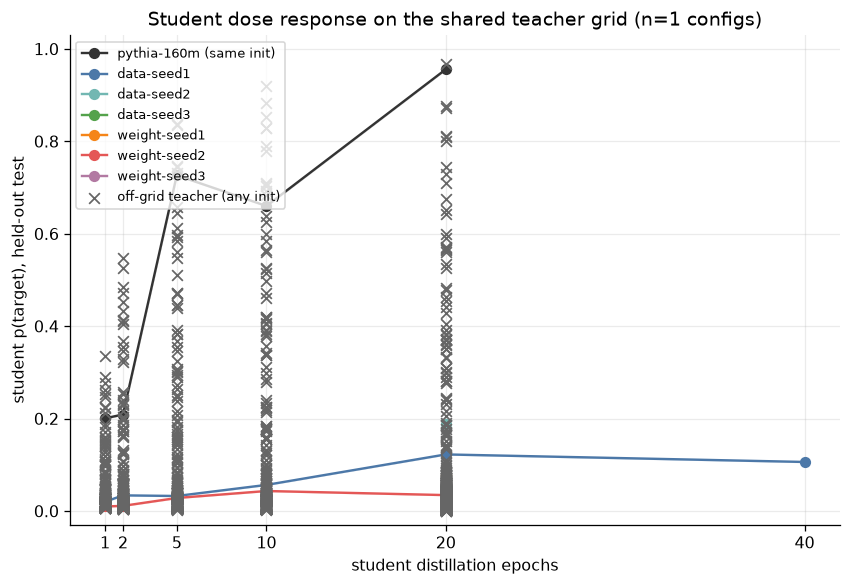

,ep1 mean,ep2 mean,ep5 mean,ep10 mean,ep20 mean,ep40 mean,ep1 n,ep2 n,ep5 n,ep10 n,ep20 n,ep40 n
pythia-160m (same init),0.201,0.209,0.727,0.660,0.956,–,1.000000,1.000000,1.000000,1.000000,1.000000,–
data-seed1,0.020,0.034,0.033,0.057,0.123,0.106,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
data-seed2,–,–,–,–,0.188,–,–,–,–,–,1.000000,–
data-seed3,–,–,–,–,0.055,–,–,–,–,–,1.000000,–
weight-seed1,–,–,–,–,0.079,–,–,–,–,–,1.000000,–
weight-seed2,0.010,0.011,0.028,0.044,0.035,–,1.000000,1.000000,1.000000,1.000000,1.000000,–
weight-seed3,–,–,–,–,0.019,–,–,–,–,–,1.000000,–


off-grid runs by init class and student dose:


In [4]:
# Fixed teacher grid for dose curves: tags every base completed at EVERY dose, so each curve
# averages the same configs at each epoch (coverage differs by dose: ep20 ran the full grid on
# all bases, ep1-10 cross-seed coverage is narrower).
doses = sorted(wide.student_epochs.unique())
by_cell = wide.groupby(["model","student_epochs"]).teacher_tag.agg(set)
dose_union = wide.groupby("student_epochs").teacher_tag.agg(set)
# A (base, dose) cell joins the shared grid only when substantially covered (same MIN_GRID_FRAC rule as the
# primary-dose grid) — a mid-backfill partial cell would otherwise shrink the intersection to whatever is done.
complete = {k: s for k, s in by_cell.items() if len(s) >= MIN_GRID_FRAC * len(dose_union[k[1]])}
partial = [k for k in by_cell.index if k not in complete]
if partial:
    print("partial (base, dose) cells excluded from the grid (their runs plot as off-grid):",
          [(BASE_LABEL[m], f"ep{e}", len(by_cell[(m, e)])) for m, e in partial])
DOSE_TAGS = sorted(set.intersection(*complete.values()))
print(f"{len(DOSE_TAGS)} teacher configs present in every complete (base, dose) cell over doses {doses} "
      f"(vs {len(COMMON_TAGS)} shared at ep={PRIMARY_EPOCH} only)")

on_grid = (wide.teacher_tag.isin(DOSE_TAGS) &
           wide.apply(lambda r: (r.model, r.student_epochs) in complete, axis=1))
dose = wide[on_grid]        # fixed teacher grid, comparable across doses & inits
stray = wide[~on_grid]      # off the shared grid: extra teacher HPs or partial (base, dose) cells

fig, ax = plt.subplots(figsize=(7.5, 5.2))
aplots.dose_response(ax, dose, x="student_epochs", y="student_test", group="model",
                     order=BASES, colors=COLOR, labels=BASE_LABEL, band_alpha=.12)
for b in BASES:
    sub = dose[dose.model.eq(b)]
    ax.scatter(sub.student_epochs, sub.student_test, s=12, alpha=.25, color=COLOR[b], zorder=2)
if len(stray):
    ax.scatter(stray.student_epochs, stray.student_test, marker="x", s=45, color="#666666", lw=1.1, zorder=4,
               label="off-grid teacher (any init)")
ax.set(xlabel="student distillation epochs", ylabel="student p(target), held-out test",
       xticks=doses, ylim=(-.03,1.03), title=f"Student dose response on the shared teacher grid (n={len(DOSE_TAGS)} configs)")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

tab = dose.pivot_table(index="model", columns="student_epochs", values="student_test", aggfunc="mean").reindex(BASES)
tab.index = [BASE_LABEL[b] for b in tab.index]; tab.columns = [f"ep{c} mean" for c in tab.columns]
cnt = dose.pivot_table(index="model", columns="student_epochs", values="student_test", aggfunc="size").reindex(BASES)
cnt.index = [BASE_LABEL[b] for b in cnt.index]; cnt.columns = [f"ep{c} n" for c in cnt.columns]
display(pd.concat([tab, cnt], axis=1).style.format({c:"{:.3f}" for c in tab.columns}, na_rep="–")
        .set_caption(f"Mean held-out test by student epoch on the shared teacher grid (n={len(DOSE_TAGS)})"))
if len(stray):
    st = stray.groupby(["init_class","student_epochs"]).student_test.agg(["size","mean","max"])
    print("off-grid runs by init class and student dose:")
    display(st.style.format({"mean":"{:.3f}","max":"{:.3f}"}))

## 3. Paired collapse against the same-init reference

Every cross-seed base is distilled from the **same** teacher configs (same number data, same teacher seed and hyperparameters) as the same-init `pythia-160m` student, at the same student dose (ep{PRIMARY_EPOCH}). Restricting to the teacher-HP grid completed for *all* bases makes the comparison paired: each point is one teacher config, x = its transfer into the same-init student, y = its transfer into the re-initialized student. Points on the dashed identity line would mean re-initialization costs nothing; points pinned to the floor mean transfer requires the shared initialization.

> The same-init ep20 reference has landed (2026-07-28 backfill, single-seed), so this paired scatter runs as designed. The `HAS_SAME_INIT` fallback — a cross-seed-only pairing (data-seed1 vs weight-seed2) — remains as a coverage guard when re-running on partial data.

101 teacher configs shared across the 7 grid student inits at ep=20


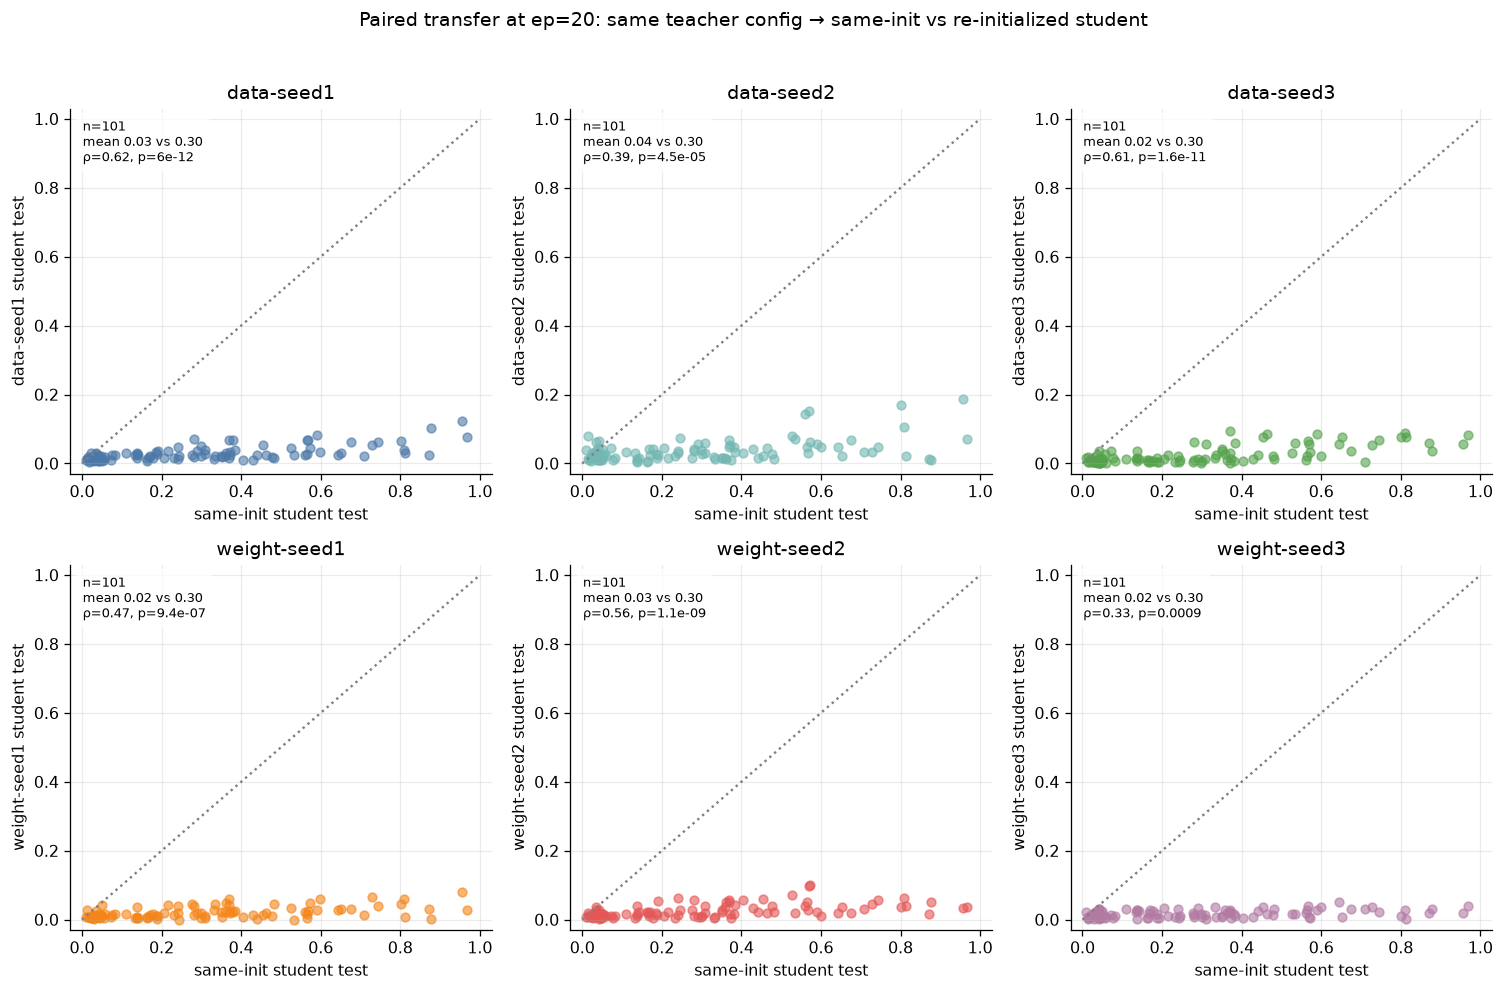

,pythia-160m (same init) test,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
mean paired Δ (vs pythia-160m (same init)),0.297,-0.268,-0.260,-0.272,-0.278,-0.272,-0.280


In [5]:
paired = pv_primary.loc[COMMON_TAGS]
if HAS_SAME_INIT:
    ref, others = SAME_INIT_MODEL, [b for b in GRID_BASES if b != SAME_INIT_MODEL]
    xlab, suptitle = "same-init student test", f"Paired transfer at ep={PRIMARY_EPOCH}: same teacher config → same-init vs re-initialized student"
else:
    # No same-init students at this dose: pair the cross-seed bases against each other instead —
    # same teacher config, same number data, only which re-initialization differs.
    ref, others = GRID_BASES[0], GRID_BASES[1:]
    xlab = f"{BASE_LABEL[ref]} student test"
    suptitle = (f"Paired transfer at ep={PRIMARY_EPOCH} (cross-init only — no same-init students at this dose): "
                f"same teacher config across re-initializations")
    print(f"no same-init runs at ep={PRIMARY_EPOCH}; pairing cross-seed bases against {BASE_LABEL[ref]}")
print(f"{len(paired)} teacher configs shared across the {len(GRID_BASES)} grid student inits at ep={PRIMARY_EPOCH}")

ncol = 3; nrow = int(np.ceil(max(len(others),1)/ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(4.4*ncol, 4.2*nrow), squeeze=False)
x = paired[ref].values
for ax, b in zip(axs.ravel(), others):
    y = paired[b].values
    _pv = spearmanr(x, y).pvalue
    aplots.identity_scatter(ax, pd.DataFrame({xlab: x, BASE_LABEL[b]: y}), x=xlab, y=BASE_LABEL[b],
                            color=COLOR[b], s=30, alpha=.6, stat="spearman", textbox=True,
                            title_stats=False,
                            extra_lines=[f"mean {y.mean():.2f} vs {x.mean():.2f}", f"p={_pv:.2g}"])
    ax.set(title=BASE_LABEL[b], xlabel=xlab, ylabel=f"{BASE_LABEL[b]} student test",
           xlim=(-.03,1.03), ylim=(-.03,1.03))
for ax in axs.ravel()[len(others):]: ax.axis("off")
fig.suptitle(suptitle, y=1.02)
plt.tight_layout(); plt.show()

row = {f"{BASE_LABEL[ref]} test": paired[ref].mean()}
for b in others: row[BASE_LABEL[b]] = (paired[b]-paired[ref]).mean()
display(pd.DataFrame(row, index=[f"mean paired Δ (vs {BASE_LABEL[ref]})"]).style.format("{:.3f}")
        .set_caption(f"Mean paired change in test transfer relative to {BASE_LABEL[ref]}"))

## 4. Does the teacher's own preference still predict transfer?

At the primary student dose, the source teacher is identical across student inits, so its held-out `validation` p(target) is the same x-value for a given teacher config; only the student initialization changes. Under the same-init student the teacher signal tracks student transfer; the question is whether that association survives re-initialization. Spearman's ρ is associative, not causal, and the teacher signal is near-saturated for many configs (limited spread).

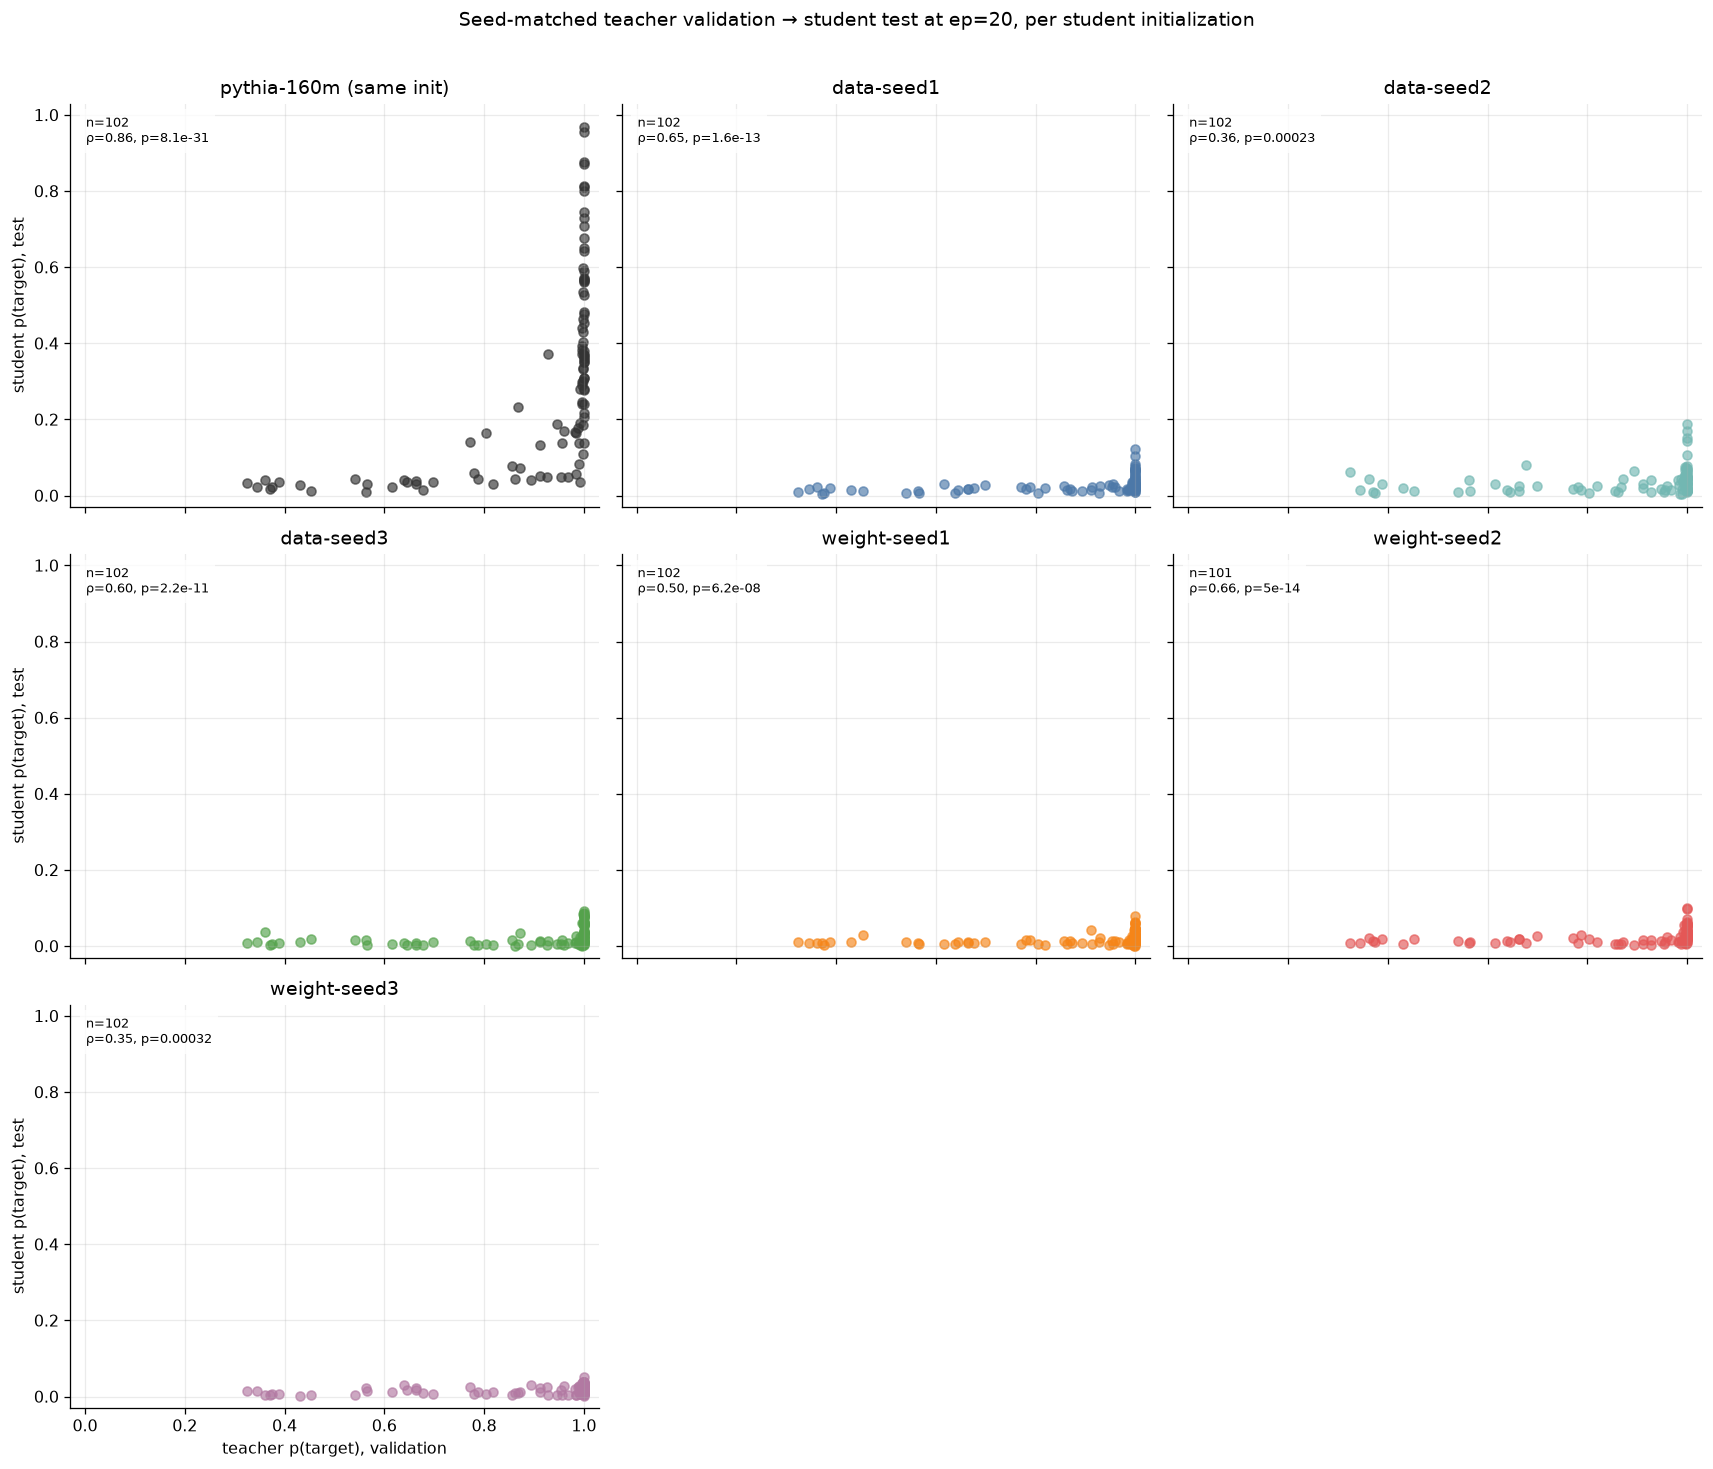

In [6]:
ncol = min(3, len(PRIMARY_BASES)); nrow = int(np.ceil(len(PRIMARY_BASES)/ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(5.0*ncol, 4.2*nrow), sharex=True, sharey=True, squeeze=False)
for ax, b in zip(axs.ravel(), PRIMARY_BASES):
    sub = primary[primary.model.eq(b)].dropna(subset=["teacher_validation","student_test"])
    ax.scatter(sub.teacher_validation, sub.student_test, s=32, alpha=.65, color=COLOR[b])
    if len(sub) > 2:
        rho, p = spearmanr(sub.teacher_validation, sub.student_test)
        ax.text(.03,.97, f"n={len(sub)}\nρ={rho:.2f}, p={p:.2g}", transform=ax.transAxes, va="top",
                bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"}, fontsize=8)
    ax.set(title=BASE_LABEL[b], xlim=(-.03,1.03), ylim=(-.03,1.03))
for ax in axs.ravel()[len(PRIMARY_BASES):]: ax.axis("off")
for ax in axs[-1]: ax.set_xlabel("teacher p(target), validation")
for ax in axs[:,0]: ax.set_ylabel("student p(target), test")
fig.suptitle(f"Seed-matched teacher validation → student test at ep={PRIMARY_EPOCH}, per student initialization", y=1.01)
plt.tight_layout(); plt.show()

## 5. Teacher hyperparameter surface across initializations

Rows are student initializations (same-init first, when it has runs at this dose), columns are the shared teacher configs, all at the primary student dose. A cell is a single run — a duplicate-key assert on `(model, teacher_tag)` at the primary dose guarantees no pooling. Columns are sorted by the same-init row's transfer strength when that reference exists; otherwise by the mean across the available (cross-init) rows. If the transferable teacher region (bright left of the reference row) survives re-initialization, the other rows stay bright in the same columns; if transfer needs the shared init, they go dark regardless of teacher HP.

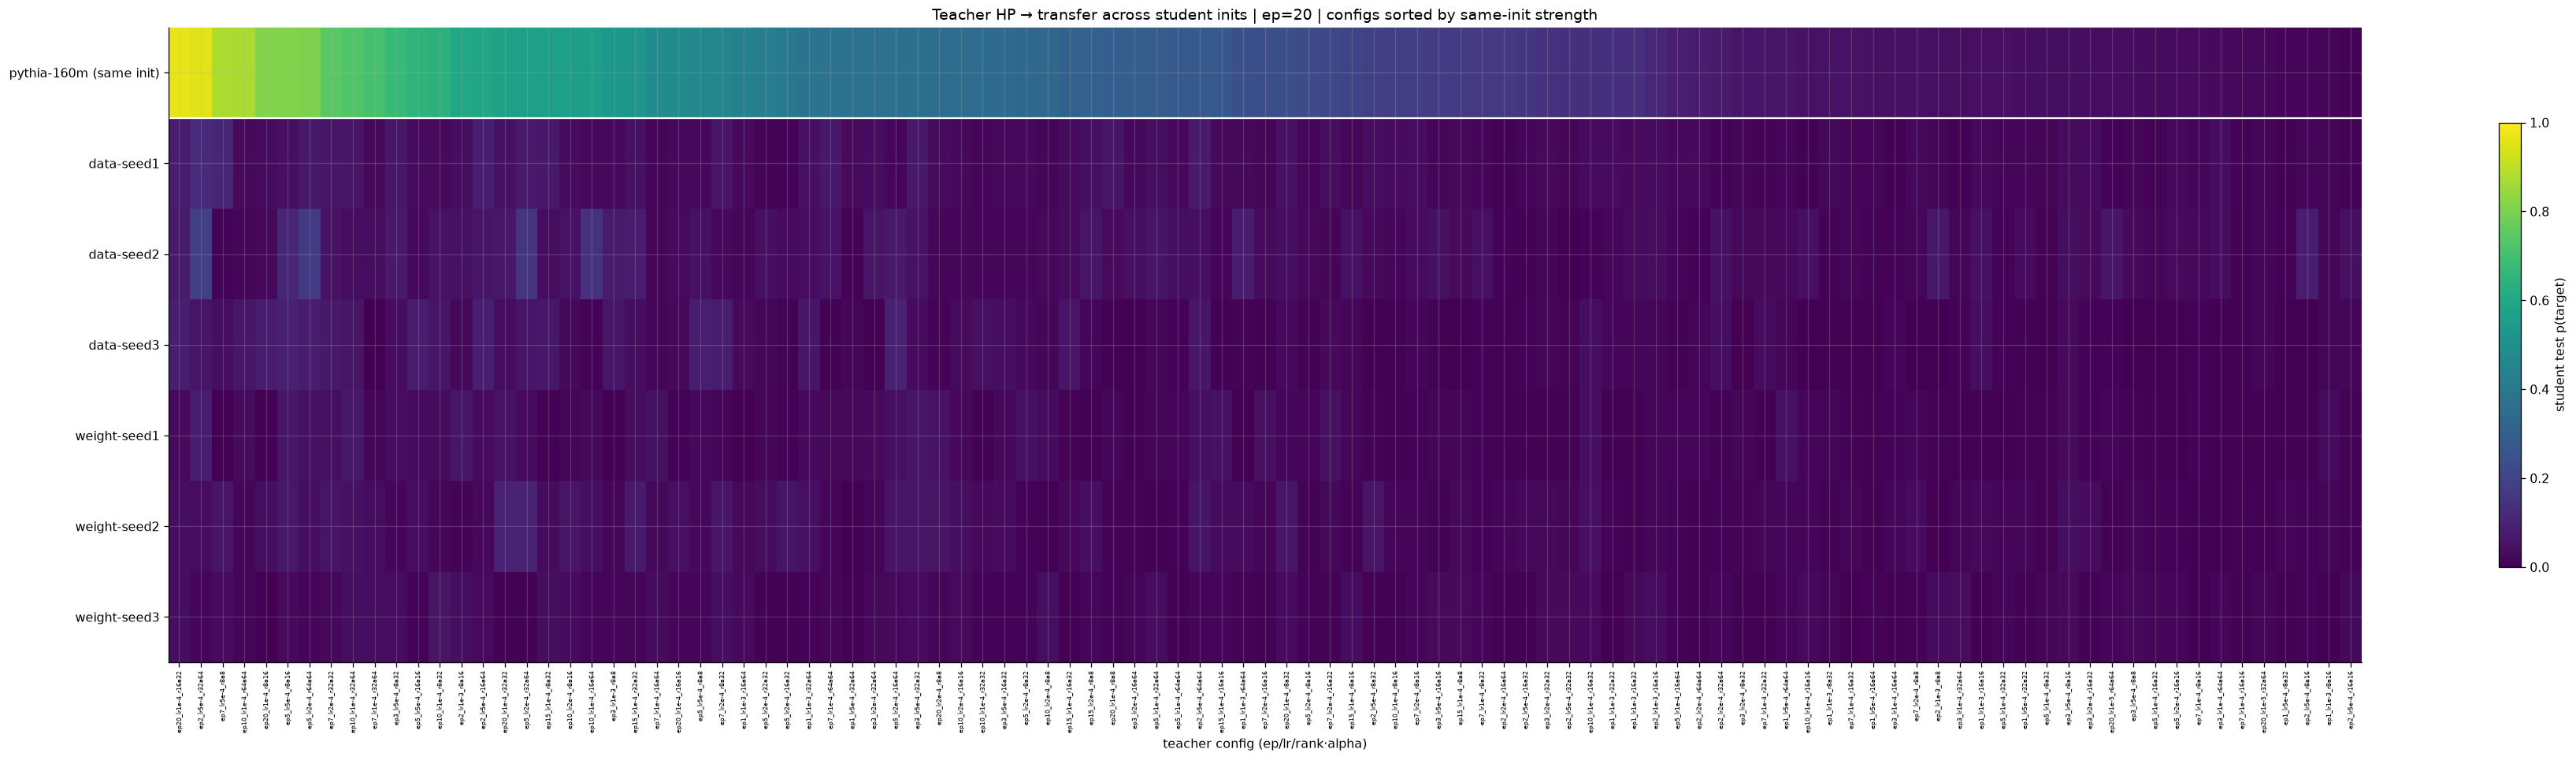

In [7]:
mat = primary.pivot_table(index="model", columns="teacher_tag", values="student_test").reindex(GRID_BASES)
mat = mat[COMMON_TAGS]  # only teacher tags shared across the bases present at this dose, so every row is comparable
order = (mat.loc[SAME_INIT_MODEL] if HAS_SAME_INIT else mat.mean(axis=0)).sort_values(ascending=False).index
mat = mat[order]

fig, ax = plt.subplots(figsize=(max(9, .32*mat.shape[1]), 1.0*len(GRID_BASES)+1.5))
# Colour only (this grid is far too wide to read a number in); ticks are set by hand below because
# the config names need rotation 90 at fontsize 5.
im = aplots.annotated_heatmap(ax, mat, vmin=0, vmax=1, origin="upper", annotate=False, show_ticks=False)
ax.set(xticks=range(mat.shape[1]), yticks=range(len(GRID_BASES)))
ax.set_xticklabels(mat.columns, rotation=90, fontsize=5)
ax.set_yticklabels([BASE_LABEL[b] for b in GRID_BASES])
if HAS_SAME_INIT: ax.axhline(0.5, color="white", lw=1.4)  # divider under the same-init reference row
fig.colorbar(im, ax=ax, label="student test p(target)", shrink=.7)
sort_lab = "same-init strength" if HAS_SAME_INIT else "mean strength (no same-init at this dose)"
ax.set(title=f"Teacher HP → transfer across student inits | ep={PRIMARY_EPOCH} | configs sorted by {sort_lab}",
       xlabel="teacher config (ep/lr/rank·alpha)")
plt.tight_layout(); plt.show()

## 5b. Full teacher-HP surface: rank/alpha × epochs, per student init and number template

The same 2D teacher-hyperparameter tables as the same-init distillation notebook (§3 there): within each grid, **x = teacher LoRA rank/alpha**, **y = teacher epochs**, one grid per **teacher learning rate**, cell value = student held-out `test` p(target) at the primary student dose. A student is included when its seed set contains `STUDENT_SEED`; a config distilled over several seeds contributes its **seed-average** p(target) rather than being dropped, and each cell is annotated `n<k>` with the number of seeds averaged (toggle `SHOW_N_SEEDS`, on here). One figure row per (student initialization × number template) combination that has runs at this dose — at ep20 that is the plain `prefix` template only, because the spliced ladder stops at ep10 (set `PRIMARY_EPOCH` ≤ 10 to bring the `spliced prefix` rows back). Empty cells are teacher configs not (yet) distilled into that student. This section reads from `treatments_all` directly (both datasets), so it is unaffected by the notebook-level `DATASET` choice.


142/714 teacher configs are seed-averaged (>1 student seed including 1); their cells show the seed-average, and 'n<k>' labels the seeds averaged
no runs at student ep=20 for: [('data-seed1', 'spliced prefix'), ('data-seed2', 'spliced prefix'), ('data-seed3', 'spliced prefix'), ('weight-seed1', 'spliced prefix'), ('weight-seed2', 'spliced prefix'), ('weight-seed3', 'spliced prefix')] (rows omitted)


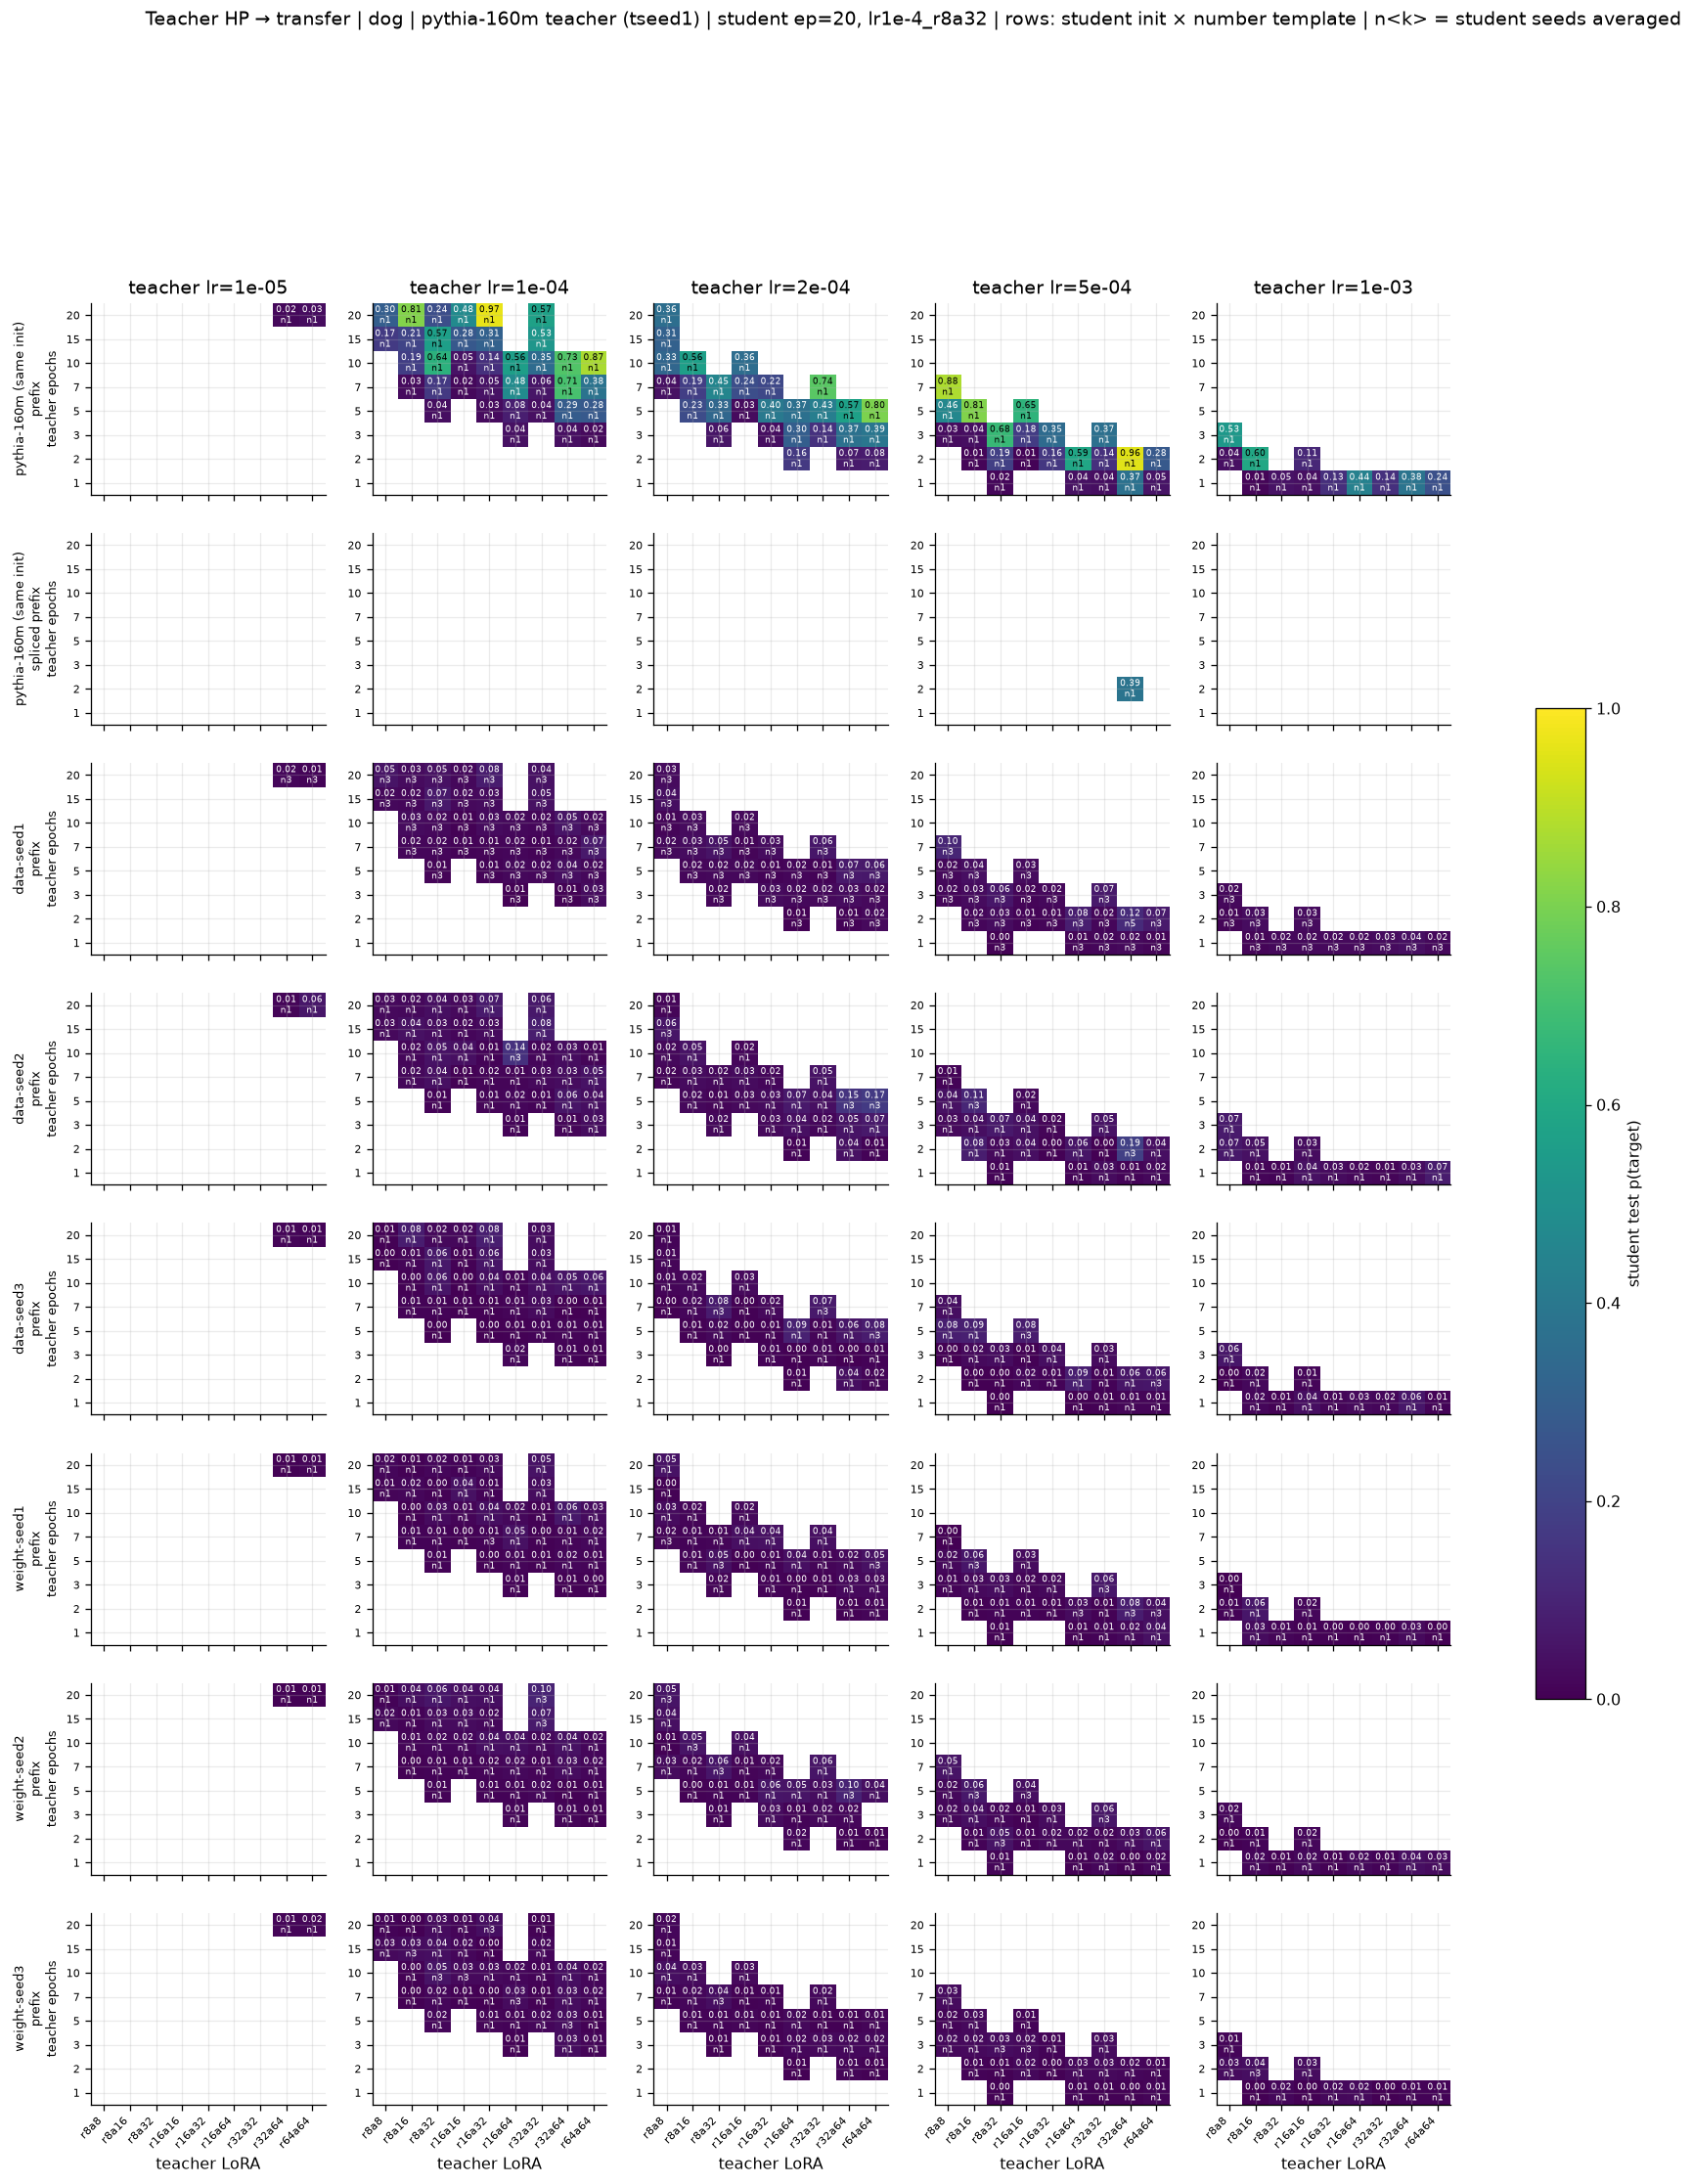

In [8]:
# Both number templates; otherwise the same fixed axes as the rest of the notebook (dog, original-model
# teacher, tseed1, fixed student LoRA) at the primary student dose. A student is included when its seed set
# contains STUDENT_SEED; a config distilled over several seeds contributes its seed-AVERAGE p(target), and
# each cell is annotated with the number of seeds averaged (n<k>).
SHOW_N_SEEDS = True   # annotate every cell with the count of student seeds averaged into its p(target)
HP_DATASETS = [DATASET, f"{DATASET}_spliced"]
DS_LABEL = {DATASET: "prefix", f"{DATASET}_spliced": "spliced prefix"}

hp_all = treatments_all[treatments_all.animal.eq(ANIMAL) & treatments_all.numbers_base.eq(NUMBERS_BASE) &
                        treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.dataset.isin(HP_DATASETS) &
                        treatments_all.set.eq("test") &
                        treatments_all.student_tag.eq(f"ep{PRIMARY_EPOCH}_{STUDENT_LORA}") &
                        treatments_all.student_seeds.map(lambda s: STUDENT_SEED in s)].copy()
assert len(hp_all), "no runs for the HP-surface slice"
hp_all["teacher_lora"] = hp_all.apply(lambda x: f"r{x.teacher_rank}a{x.teacher_alpha}", axis=1)
hp_all["n_seeds"] = hp_all.student_seeds.map(len)   # seeds averaged into this config's p(target) (>= 1)
DUP = ["model", "dataset", "teacher_lr", "teacher_epochs", "teacher_lora"]
assert not hp_all.duplicated(DUP).any(), "duplicate teacher-HP keys would pool multiple runs per heatmap cell"
n_multi = int((hp_all.n_seeds > 1).sum())
if n_multi:
    print(f"{n_multi}/{len(hp_all)} teacher configs are seed-averaged (>1 student seed including {STUDENT_SEED}); "
          f"their cells show the seed-average, and 'n<k>' labels the seeds averaged")

# Shared axes across every grid so the figure rows are visually comparable. Rows self-filter to the
# (init, template) combos with runs at this dose — the spliced ladder stops at ep10, so at ep20 only
# the plain rows render.
LORAS = sorted(hp_all.teacher_lora.unique(), key=lambda x: tuple(map(int, re.findall(r"\d+", x))))
EPOCHS = sorted(hp_all.teacher_epochs.unique())
LRS = sorted(hp_all.teacher_lr.unique())
present = set(map(tuple, hp_all[["model","dataset"]].drop_duplicates().values))
ROWS = [(b, ds) for b in BASES for ds in HP_DATASETS if (b, ds) in present]
dropped = [(BASE_LABEL[b], DS_LABEL[ds]) for b in BASES for ds in HP_DATASETS if (b, ds) not in present]
if dropped: print(f"no runs at student ep={PRIMARY_EPOCH} for: {dropped} (rows omitted)")

cov = pd.crosstab([hp_all.model.map(BASE_LABEL), hp_all.dataset.map(DS_LABEL)], hp_all.teacher_lr)
cov = cov.reindex([(BASE_LABEL[b], DS_LABEL[ds]) for b, ds in ROWS])
cov.columns = [f"lr={c:.0e}" for c in cov.columns]
cov["total"] = cov.sum(axis=1)
display(cov.style.set_caption(f"Covered teacher configs per student init × template × teacher lr (student ep={PRIMARY_EPOCH})"))

fig, axs = plt.subplots(len(ROWS), len(LRS), figsize=(3.9*len(LRS), 2.6*len(ROWS)), squeeze=False)
image = None
for r, (b, ds) in enumerate(ROWS):
    sub = hp_all[hp_all.model.eq(b) & hp_all.dataset.eq(ds)]
    for c, lr in enumerate(LRS):
        ax = axs[r, c]
        cell = sub[sub.teacher_lr.eq(lr)]
        q = (cell.pivot(index="teacher_epochs", columns="teacher_lora", values="p")
             .reindex(index=EPOCHS, columns=LORAS))
        qn = (cell.pivot(index="teacher_epochs", columns="teacher_lora", values="n_seeds")
              .reindex(index=EPOCHS, columns=LORAS))
        # Ticks are set by hand below (rotation/fontsize and the bottom-row-only x labels are this
        # figure's own contract), so the shared heatmap draws colour + `n<k>` labels only.
        image = aplots.annotated_heatmap(ax, q, counts=qn if SHOW_N_SEEDS else None, vmin=0, vmax=1,
                                         mid=.55, cell_fontsize=5.5, show_ticks=False)
        ax.set(xticks=range(len(LORAS)), yticks=range(len(EPOCHS)))
        ax.set_yticklabels(EPOCHS, fontsize=7)
        if r == len(ROWS)-1:
            ax.set_xticklabels(LORAS, rotation=45, ha="right", fontsize=7); ax.set_xlabel("teacher LoRA")
        else:
            ax.set_xticklabels([])
        if r == 0: ax.set_title(f"teacher lr={lr:.0e}")
        if c == 0: ax.set_ylabel(f"{BASE_LABEL[b]}\n{DS_LABEL[ds]}\nteacher epochs", fontsize=8)
fig.colorbar(image, ax=axs.ravel().tolist(), label="student test p(target)", shrink=.55)
fig.suptitle(f"Teacher HP → transfer | {ANIMAL} | {NUMBERS_BASE} teacher (tseed{TEACHER_SEED}) | "
             f"student ep={PRIMARY_EPOCH}, {STUDENT_LORA} | rows: student init × number template"
             + (" | n<k> = student seeds averaged" if SHOW_N_SEEDS else ""), y=1.005)
plt.show()


## 6. Specificity and ranked configs

At the primary student dose, high `test` with low `off_topic` is more specific transfer. Points are colored by initialization; the same-init cluster should sit high-right of the cross-init cluster if re-initialization suppresses on-target transfer. The table's transparent ranking score is `test − off_topic`, not a definitive objective.

> **Coverage.** The dog students (all initializations) were scored only on the `test` and `storytelling` prompt sets — `off_topic` was not scored — so the specificity scatter and the `off_topic` / `test − off_topic` columns render empty here; the ranking falls back to `test`. Backfill the student `off_topic` evals to repopulate them.

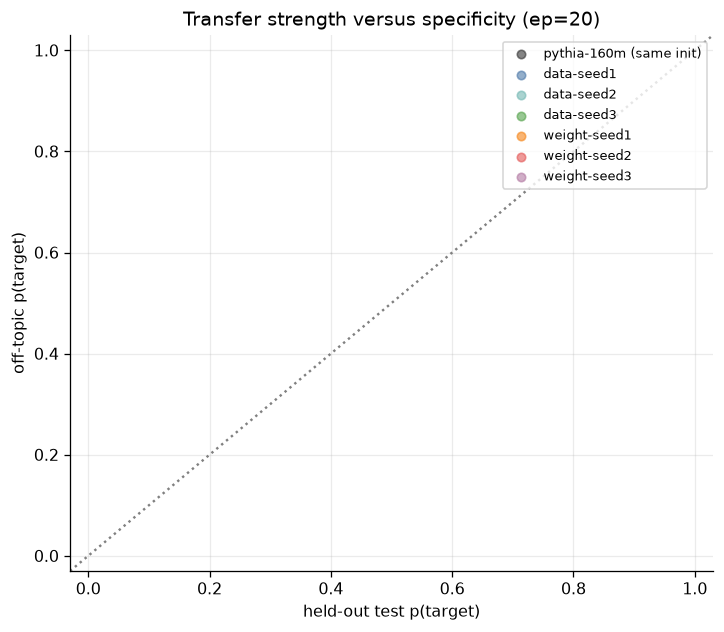

,student init,teacher_tag,teacher_validation,student_test,student_off_topic,test_minus_offtopic,loss
162,pythia-160m (same init),ep20_lr1e-4_r16a32,1.000,0.968,–,–,1.370
252,pythia-160m (same init),ep2_lr5e-4_r32a64,1.000,0.956,–,–,1.427
507,pythia-160m (same init),ep7_lr5e-4_r8a8,1.000,0.877,–,–,1.366
27,pythia-160m (same init),ep10_lr1e-4_r64a64,1.000,0.872,–,–,1.471
172,pythia-160m (same init),ep20_lr1e-4_r8a16,1.000,0.813,–,–,1.522
427,pythia-160m (same init),ep5_lr5e-4_r8a16,1.000,0.810,–,–,1.316
407,pythia-160m (same init),ep5_lr2e-4_r64a64,1.000,0.801,–,–,1.496
487,pythia-160m (same init),ep7_lr2e-4_r32a32,1.000,0.744,–,–,1.458
22,pythia-160m (same init),ep10_lr1e-4_r32a64,1.000,0.729,–,–,1.329
457,pythia-160m (same init),ep7_lr1e-4_r32a64,1.000,0.709,–,–,1.633


,n,test_mean,offtopic_mean,spec_mean
pythia-160m (same init),102,0.298,–,–
data-seed1,102,0.029,–,–
data-seed2,102,0.037,–,–
data-seed3,102,0.025,–,–
weight-seed1,102,0.020,–,–
weight-seed2,101,0.025,–,–
weight-seed3,102,0.017,–,–


Overall teacher validation ↔ student test association (all inits pooled, ep=20): ρ=0.450, p=7.32e-37
Best test−off-topic: pythia-160m (same init), teacher ep20_lr1e-4_r16a32, test=0.968, off-topic=nan


In [9]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
for b in PRIMARY_BASES:
    sub = primary[primary.model.eq(b)].dropna(subset=["student_test","student_off_topic"])
    ax.scatter(sub.student_test, sub.student_off_topic, s=28, alpha=.6, color=COLOR[b], label=BASE_LABEL[b])
ax.axline((0,0), slope=1, color=".5", ls=":")
ax.set(xlabel="held-out test p(target)", ylabel="off-topic p(target)", xlim=(-.03,1.03), ylim=(-.03,1.03),
       title=f"Transfer strength versus specificity (ep={PRIMARY_EPOCH})")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

cols = ["model","teacher_tag","teacher_validation","student_test","student_off_topic","test_minus_offtopic","loss"]
top = primary.sort_values(["test_minus_offtopic","student_test"], ascending=False)[cols].head(25).copy()
top["model"] = top.model.map(BASE_LABEL)
fmt = {c:"{:.3f}" for c in ["teacher_validation","student_test","student_off_topic","test_minus_offtopic","loss"]}
display(top.rename(columns={"model":"student init"}).style.format(fmt, na_rep="–").set_caption("Top configs by test − off-topic"))

perbase = primary.groupby("model").agg(n=("student_test","size"), test_mean=("student_test","mean"),
        offtopic_mean=("student_off_topic","mean"), spec_mean=("test_minus_offtopic","mean")).reindex(PRIMARY_BASES)
perbase.index = [BASE_LABEL[b] for b in perbase.index]
rho, p = spearmanr(primary.teacher_validation, primary.student_test, nan_policy="omit")
display(perbase.style.format({c:"{:.3f}" for c in perbase.columns if c!="n"}, na_rep="–").set_caption("Per-initialization specificity"))
print(f"Overall teacher validation ↔ student test association (all inits pooled, ep={PRIMARY_EPOCH}): ρ={rho:.3f}, p={p:.3g}")
best = primary.sort_values(["test_minus_offtopic","student_test"], ascending=False).iloc[0]
print(f"Best test−off-topic: {BASE_LABEL[best.model]}, teacher {best.teacher_tag}, "
      f"test={best.student_test:.3f}, off-topic={best.student_off_topic:.3f}")

### Interpretation checklist

- Use held-out `test`, not teacher-trained sets, for the main transfer claim; report `off_topic` beside it once the dog students' `off_topic` evals are backfilled (high on both is not specific).
- The base × teacher-HP sections fix the student dose at `PRIMARY_EPOCH` (20, plain template only — the spliced ladder stops at ep10); §2 is the only dose-varying view. All three initializations cover the full ~102-tag grid at ep20 (the same-init backfill landed 2026-07-28, single-seed).
- The headline comparison is the paired collapse in §3: same teacher config, same number data, same student dose, only the student initialization differs. The cross-vs-cross pairing tests separately whether the two re-init families differ from each other.
- Distinguish the two cross-seed families: `data-seed*` re-shuffles the training-data order; `weight-seed*` re-draws the initial weights. All three re-seeds of each family are on the ep20 grid (`data-seed2/3` and `weight-seed1/3` are ep20-only; the dose ladders exist for `data-seed1`/`weight-seed2`); the families — and seeds within a family — can collapse differently.
- The `rng` controls include the ep20 dose (3 ft seeds per base, test p ≈ 0.001–0.009) and set the no-signal floor; no untuned-base `p(target)` was persisted.
- The teacher `validation` signal is near-saturated across the HP grid, so §4 associations have limited x-spread; do not over-read a flat ρ.
- Seed depth is uneven (3-seed means on cross `data-seed1` ep20 after the reseed, mostly single-seed elsewhere); match seed coverage before reporting seed-level uncertainty or stable cross-minus-same intervals.


## 7. Shared focus-20 × top-10 distributions — box plots and upper-tail percentiles
#
Every earlier per-init comparison in this notebook fixes ONE student cell (the std recipe).
This section instead aggregates over the **matched multi-cell design**: the 20 focus-20
student-HP cells × the dog top-10 teacher configs, restricted to (teacher × cell) combos
computed on **all six** cross-init bases — 200/200 combos exist everywhere, so each box is
the identical design. Same-init has no focus-20 coverage and is deliberately absent.
Row unit: one (teacher, student-cell) run (student seed 1), test/prob p(dog).

shared (teacher x cell) combos on all 6 bases: 200 (design max = 10 teachers x 20 cells = 200)


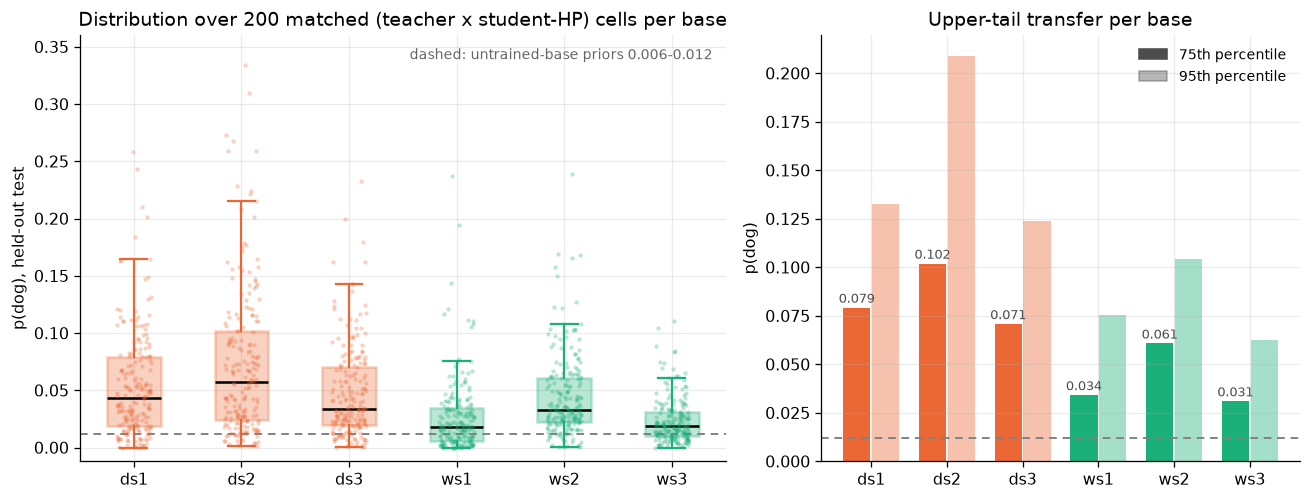

,n,p25,median,p75,p95,max
base,,,,,,
ds1,200.0000,0.0192,0.0434,0.0793,0.1324,0.2583
ds2,200.0000,0.0240,0.0570,0.1020,0.2091,0.3337
ds3,200.0000,0.0199,0.0339,0.0708,0.1241,0.2330
ws1,200.0000,0.0061,0.0178,0.0342,0.0756,0.2376
ws2,200.0000,0.0220,0.0330,0.0608,0.1042,0.2393
ws3,200.0000,0.0104,0.0188,0.0310,0.0627,0.1105


In [10]:
_cells20 = frames.read_cell_manifest(ROOT / "run_logs/focus20_cells.json")
_top10 = frames.read_cell_manifest(ROOT / "run_logs/dog_top20krungs_configs.json")[:10]
_SROOT = OUTPUT_ROOT / "students" / "dog"
_CROSS = ["pythia-160m-data-seed1", "pythia-160m-data-seed2", "pythia-160m-data-seed3",
          "pythia-160m-weight-seed1", "pythia-160m-weight-seed2", "pythia-160m-weight-seed3"]
_LBL = ["ds1", "ds2", "ds3", "ws1", "ws2", "ws3"]

def _test_p(doc):
    s = frames.summary_set_block(doc, "test")
    return s.get("p_target_mean") if s and s.get("scoring") == "prob" else None

# Enumerate the candidate cell dirs, then read them in one batched, cached sweep: cells with no
# readable summary are simply absent from the mapping, which is what the per-path .exists() did.
_keys20 = [(b, t, c) for b in _CROSS for t in _top10 for c in _cells20]
_rels20 = [str((_SROOT / b / "teacher-pythia-160m" / f"{t}_tseed1" / "ex10-20_prefix_n100k" / c)
               .relative_to(OUTPUT_ROOT)) for b, t, c in _keys20]
_docs20 = frames.load_cell_summaries(OUTPUT_ROOT, _rels20)

_vals = {b: {} for b in _CROSS}
for (_b, _t, _c), _rel in zip(_keys20, _rels20):
    _v = _test_p(_docs20.get(_rel))
    if _v is not None: _vals[_b][(_t, _c)] = _v
_shared = set.intersection(*[set(v) for v in _vals.values()])
_arrs = [np.array([_vals[_b][k] for k in sorted(_shared)]) for _b in _CROSS]
print(f"shared (teacher x cell) combos on all 6 bases: {len(_shared)} "
      f"(design max = {len(_top10)} teachers x {len(_cells20)} cells = {len(_top10)*len(_cells20)})")

_cols = ["#eb6834"]*3 + ["#1baf7a"]*3
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.35, 1]})
for i, (a, c) in enumerate(zip(_arrs, _cols)):
    ax1.boxplot([a], positions=[i], widths=0.5, patch_artist=True, showfliers=False,
                boxprops={"facecolor": c, "alpha": 0.30, "edgecolor": c, "linewidth": 1.6},
                whiskerprops={"color": c, "linewidth": 1.4}, capprops={"color": c, "linewidth": 1.4},
                medianprops={"color": "black", "linewidth": 1.6})
    ax1.scatter(i + aplots.jitter(len(a), 0.16, seed=0), a, s=7, alpha=0.30, color=c, linewidths=0, zorder=3)
# 0.012 = the top of the untrained-base p(dog) prior range across these six bases (frozen value;
# the per-base priors span 0.006-0.012, see tf.load_priors `test_prior` on the re-seeded bases).
ax1.axhline(0.012, color="0.5", linewidth=1.2, linestyle=(0, (4, 3)))
ax1.text(0.98, 0.97, "dashed: untrained-base priors 0.006-0.012", transform=ax1.transAxes,
         ha="right", va="top", fontsize=9, color="0.4")
ax1.set(xticks=range(6), ylabel="p(dog), held-out test", ylim=(-0.012, 0.36),
        title=f"Distribution over {len(_shared)} matched (teacher x student-HP) cells per base")
ax1.set_xticklabels(_LBL)

x = np.arange(6); w = 0.36
_p75 = [np.percentile(a, 75) for a in _arrs]; _p95 = [np.percentile(a, 95) for a in _arrs]
b1 = ax2.bar(x - w/2 - 0.01, _p75, w, color=_cols)
ax2.bar(x + w/2 + 0.01, _p95, w, color=_cols, alpha=0.40)
for bb, v in zip(b1, _p75):
    ax2.annotate(f"{v:.3f}", (bb.get_x()+bb.get_width()/2, v), textcoords="offset points",
                 xytext=(0, 3), ha="center", fontsize=8, color="0.3")
ax2.axhline(0.012, color="0.5", linewidth=1.2, linestyle=(0, (4, 3)))
import matplotlib.patches as _mp
ax2.legend(handles=[_mp.Patch(color="0.3", label="75th percentile"),
                    _mp.Patch(color="0.3", alpha=0.40, label="95th percentile")], frameon=False, fontsize=9)
ax2.set(xticks=x, title="Upper-tail transfer per base", ylabel="p(dog)")
ax2.set_xticklabels(_LBL)
fig.suptitle("")
plt.tight_layout(); plt.show()

import pandas as _pd
_tbl = _pd.DataFrame({"base": _LBL, "n": [len(a) for a in _arrs],
                      "p25": [np.percentile(a, 25) for a in _arrs],
                      "median": [np.median(a) for a in _arrs],
                      "p75": _p75, "p95": _p95, "max": [a.max() for a in _arrs]}).set_index("base")
display(_tbl.style.format("{:.4f}").set_caption(
    "dog | 200 shared (top-10 teacher x focus-20 cell) combos, identical on every base | "
    "student seed 1 | test/prob | orange = data-seed, green = weight-seed"))

## 8. Deck figure — cross-init transfer over the 200 matched cells (headline_deck slide 6)

Slide 6 of `docs/results/headline_deck.pptx`, rebuilt from this notebook's own §7 frames
(`_arrs`, `_shared`, `_LBL`) so the deck panel and the live tree can never drift apart.

- **Row unit**: one `(top-10 teacher config × focus-20 student-HP cell)` run at student seed 1,
  scored as held-out `test` p(dog) (prob scoring).
- **Selection**: the intersection of (teacher × cell) combos present on **all six** cross-init
  bases — the identical design on every base. Same-init has no focus-20 coverage, so it is absent
  and enters only as the std-cell mean quoted in the footer.
- **Aggregation**: left panel shows the full per-cell distribution (box + jittered points);
  right panel is the 75th/95th **percentile over cells** per base.
- The dashed line is the untrained-base animal prior (`transfer_factors.load_priors`, `behav_prior`),
  drawn at the largest of the six base priors; the annotation quotes the live range.


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/pandas/core/algorithms.py:1715: UserWarning: short_model: 'pythia-160m@step100000' is not a pythia-160m-family name; passing it through unchanged. 160m-keyed joins will silently drop these rows — extend the label mapping before analyzing non-160m runs.
  return lib.map_infer(values, mapper)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/pandas/core/algorithms.py:1715: UserWarning: short_model: 'pythia-160m@step125000' is not a pythia-160m-family name; passing it through unchanged. 160m-keyed joins will silently drop these rows — extend the label mapping before analyzing non-160m runs.
  return lib.map_infer(values, mapper)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/pandas/core/algorithms.py:1715: UserWarning: short_model: 'pythia-160m@step25000' is not a pythia-160m-family name; passing it through unchanged. 160m-keyed joins will silently dr

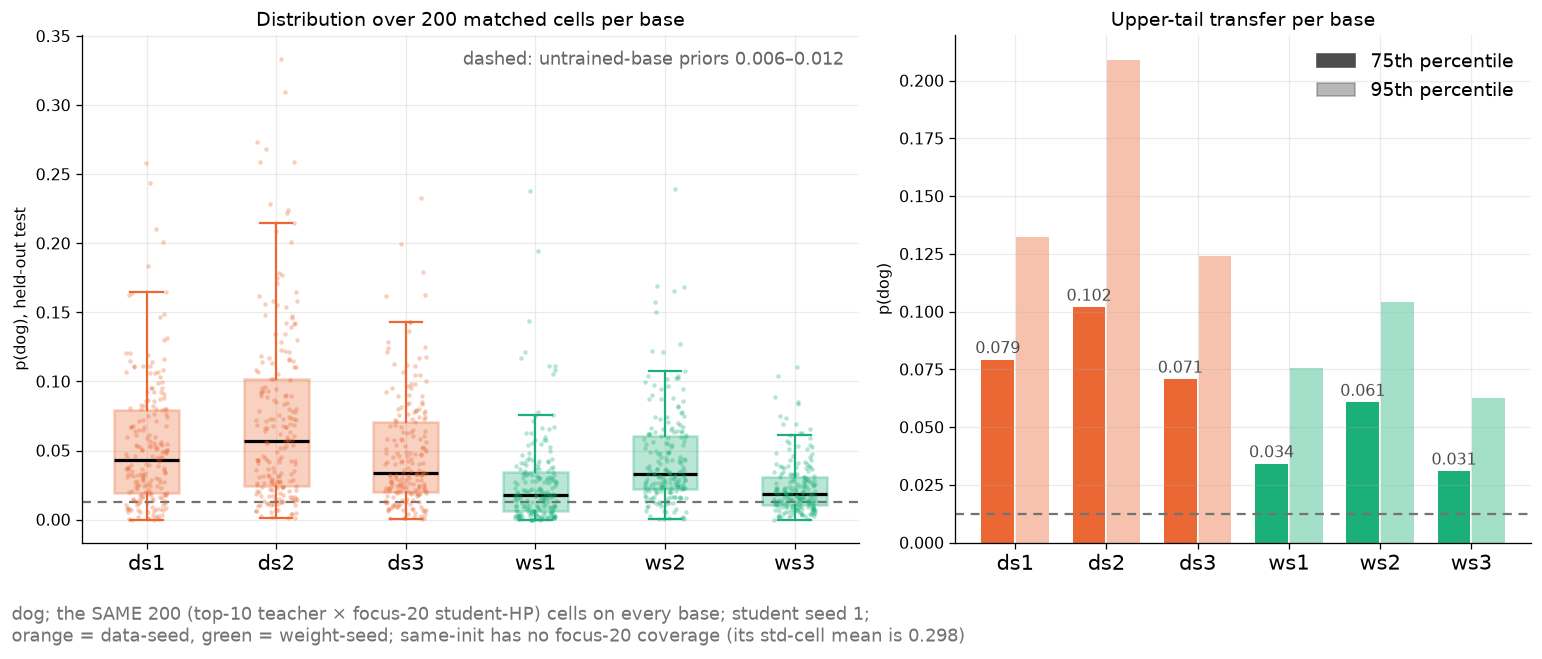

,n_cells,prior,p75_live,p75_deck_0816,p75_delta,p95_live
base,,,,,,
ds1,200,0.0119,0.0793,0.0790,0.0003,0.1324
ds2,200,0.0111,0.1020,0.1020,-0.0000,0.2091
ds3,200,0.0085,0.0708,0.0710,-0.0002,0.1241
ws1,200,0.0061,0.0342,0.0340,0.0002,0.0756
ws2,200,0.0124,0.0608,0.0610,-0.0002,0.1042
ws3,200,0.0064,0.0310,0.0310,0.0000,0.0627


In [11]:
from subliminal_learning.analysis import transfer_factors as _tf
import matplotlib.patches as _mp

# Untrained-base priors for the six cross-init bases (live, not the deck's hardcoded band).
_priors = _tf.load_priors(OUTPUT_ROOT).set_index(["animal", "base_label"]).behav_prior
_BASE_LBL = dict(zip(_LBL, (BASE_LABEL[b] for b in _CROSS)))   # short code -> prior's base_label
_pri = [float(_priors[(ANIMAL, _BASE_LBL[l])]) for l in _LBL]
_pri_line = max(_pri)

_d75 = [np.percentile(a, 75) for a in _arrs]
_d95 = [np.percentile(a, 95) for a in _arrs]
_same_mean = primary.loc[primary.model.eq(SAME_INIT_MODEL), "student_test"].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.35, 1]})
for i, (a, c) in enumerate(zip(_arrs, _cols)):
    ax1.boxplot([a], positions=[i], widths=0.5, patch_artist=True, showfliers=False,
                boxprops={"facecolor": c, "alpha": 0.30, "edgecolor": c, "linewidth": 1.6},
                whiskerprops={"color": c, "linewidth": 1.4}, capprops={"color": c, "linewidth": 1.4},
                medianprops={"color": "black", "linewidth": 2.0})
    ax1.scatter(i + aplots.jitter(len(a), 0.16, seed=0), a, s=8, alpha=0.32, color=c, linewidths=0, zorder=3)
ax1.axhline(_pri_line, color="0.45", linewidth=1.4, linestyle=(0, (4, 3)))
ax1.text(0.98, 0.97, f"dashed: untrained-base priors {min(_pri):.3f}\u2013{max(_pri):.3f}",
         transform=ax1.transAxes, ha="right", va="top", fontsize=11, color="0.4")
ax1.set(xticks=range(6), ylabel=f"p({ANIMAL}), held-out test",
        title=f"Distribution over {len(_shared)} matched cells per base")
ax1.set_xticklabels(_LBL, fontsize=13)

_x = np.arange(6); _w = 0.36
_b1 = ax2.bar(_x - _w/2 - 0.01, _d75, _w, color=_cols)
ax2.bar(_x + _w/2 + 0.01, _d95, _w, color=_cols, alpha=0.40)
for _bb, _v in zip(_b1, _d75):
    ax2.annotate(f"{_v:.3f}", (_bb.get_x() + _bb.get_width()/2, _v), textcoords="offset points",
                 xytext=(0, 4), ha="center", fontsize=10, color="0.3")
ax2.axhline(_pri_line, color="0.45", linewidth=1.4, linestyle=(0, (4, 3)))
ax2.legend(handles=[_mp.Patch(color="0.3", label="75th percentile"),
                    _mp.Patch(color="0.3", alpha=0.40, label="95th percentile")],
           frameon=False, fontsize=12, loc="upper right")
ax2.set(xticks=_x, title="Upper-tail transfer per base", ylabel=f"p({ANIMAL})")
ax2.set_xticklabels(_LBL, fontsize=13)

fig.text(0.01, -0.02,
         f"{ANIMAL}; the SAME {len(_shared)} (top-10 teacher \u00d7 focus-20 student-HP) cells on every base; "
         f"student seed {STUDENT_SEED};\n"
         f"orange = data-seed, green = weight-seed; same-init has no focus-20 coverage "
         f"(its std-cell mean is {_same_mean:.3f})",
         ha="left", va="top", fontsize=11, color="0.45")
plt.tight_layout(); plt.show()

# Frozen record: the 75th percentiles as they appeared on headline_deck slide 6 (2026-08-16).
# Kept verbatim so `p75_delta` measures drift of the live tree against that published figure.
_deck75 = {"ds1": 0.079, "ds2": 0.102, "ds3": 0.071, "ws1": 0.034, "ws2": 0.061, "ws3": 0.031}
_deck = pd.DataFrame({"base": _LBL, "n_cells": [len(a) for a in _arrs], "prior": _pri,
                      "p75_live": _d75, "p75_deck_0816": [_deck75[l] for l in _LBL],
                      "p75_delta": [a - _deck75[l] for a, l in zip(_d75, _LBL)],
                      "p95_live": _d95}).set_index("base")
display(_deck.style.format("{:.4f}", subset=[c for c in _deck.columns if c != "n_cells"]).set_caption(
    f"Slide-6 values: live percentiles over the {len(_shared)} matched cells vs the deck's 2026-08-16 numbers | "
    f"{ANIMAL} | student seed {STUDENT_SEED} | test/prob"))
